In [2]:
# Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as sk
from scipy import optimize


In [3]:
# Generating data with respect to Logistic Regression assumption

N = 500 
y = np.hstack(
    [
        np.ones(N),
        np.zeros(N)
    ]
)

# Real Pararmeter values
mu0 = np.array([2, 3])
sigma20 = np.array([1.5, 1.5])

mu1 = np.array([5.7, 8.45])
sigma21 = np.array([1.5, 1.5])

# Generating data with respect to X|Y=1 ~ Normal(mu, sigma2)
X1 = np.random.normal(
    loc=mu1, 
    scale=sigma21,
    size=(N, 2)
)

# Generating data with respect to X|Y=0 ~ Normal(mu, sigma2)
X0 = np.random.normal(
    loc=mu0,
    scale=sigma20, 
    size=(N, 2)
)

# data integration
X = np.vstack([X1, X0])
dataset = np.concatenate([X, y.reshape(1000, 1)], axis=1)
df = pd.DataFrame(dataset, columns=['X0', 'X1', 'Y'])

X_train, X_test, y_train, y_test = sk.model_selection.train_test_split(
                                                                        df[['X0', 'X1']], df['Y'],
                                                                        test_size=0.2, shuffle=True
                                                                        )

train_df = pd.DataFrame(
    X_train,
    columns=['X0', 'X1']
)

train_df['Y'] = y_train

test_df = pd.DataFrame(
    X_test,
    columns=['X0', 'X1']
)

test_df['Y'] = y_test


train_df.head()

,X0,X1,Y
890,-0.869768,4.227504,0.0
494,6.594292,9.032206,1.0
23,5.055810,11.461059,1.0
243,5.761647,9.765556,1.0
514,2.939263,1.166057,0.0


In [4]:
train_df.shape

(800, 3)

[Text(0, 0.5, 'X1'), Text(0.5, 0, 'X0')]

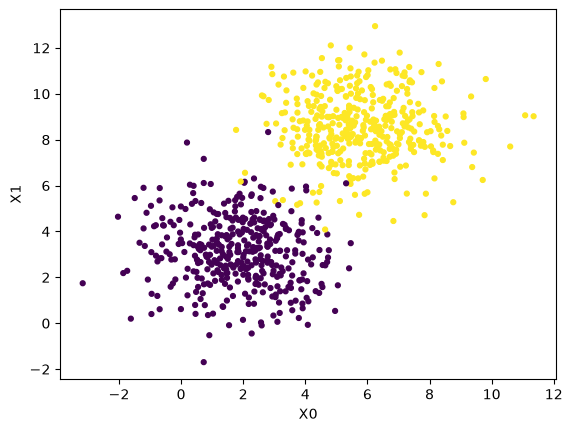

In [5]:
# Plot
fig, ax = plt.subplots(1, 1)
ax.scatter(train_df['X0'], train_df['X1'], s=12, c=train_df['Y'])
ax.set(
    ylabel='X1',
    xlabel='X0',
    
)

In [6]:
train_df

,X0,X1,Y
890,-0.869768,4.227504,0.0
494,6.594292,9.032206,1.0
23,5.055810,11.461059,1.0
243,5.761647,9.765556,1.0
514,2.939263,1.166057,0.0
...,...,...,...
280,5.851294,8.387291,1.0
308,4.895716,9.025396,1.0
383,6.128627,7.359346,1.0
51,6.005838,10.815877,1.0


In [7]:
# Converting DataFrame to numpy dataset to utilizing better in model

train_df = train_df.to_numpy()

test_df = test_df.to_numpy()

X = train_df[:, :2] # Features
Y = train_df[:, -1] # Label
Xt = test_df[:, :2] # Features
Yt = test_df[:, -1] # Label

# sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


class LogisticRegressionFromScratch:

    TEST_ACC = 0
    TRAIN_ACC = 0

    def __init__(self, lr, n_iter):

        self.lr = lr
        self.n_iter = n_iter
        self.weights = None
        self.bias = None
        self.loss_history = list()
        self.weights_history= list()
        self.train_acc_history = list()

    # Learning weights
    def train(self, X, Y):

        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0

        theta = np.concatenate([self.weights, [self.bias]])

        for item in range(self.n_iter):

            self.weights_history.append(theta.copy())
            self.loss_history.append(self.loss_function(theta[:-1], theta[-1]))

            grad = optimize.approx_fprime(theta, lambda t: self.loss_function(t[:-1], t[-1]) , epsilon=0.005)

            theta += self.lr * grad

        self.weights = theta[:-1]
        self.bias = theta[-1]

        self.train_acc_history.append
        (
            self.train_acc(X, Y)
        )
        
        return self.weights, self.bias
    
    def loss_function(self, w, b):

        n_samples = X.shape[0]
        loss = 0

        for item in range(n_samples):

            prob = sigmoid(np.dot(X[item], w) + b)
            prob = np.clip(prob, 1e-15, 1 - 1e-15)

            p = np.log(prob)
            k = np.log(1 - prob)

            loss += Y[item] * p + (1 - Y[item]) * k

        return loss

    def predict(self, x, y):
        prob1 = 1 / (1 + np.exp(-(np.dot(x, self.weights) + self.bias)))
        if (prob1 > .5 and y==1) or (prob1 <= 0.5 and y==0) or prob1==0.5:
            return True
        else:
            return False


    def test_acc(self, X, y):

        temp = 0

        for item in range(X.shape[0]):
            if self.predict(X[item], y[item]):
                temp += 1

        TEST_ACC = temp / X.shape[0]

        return TEST_ACC


    def train_acc(self, X, y):
    
            temp = 0
    
            for item in range(X.shape[0]):
                if self.predict(X[item], y[item]):
                    temp += 1
    
            TRAIN_ACC = temp / X.shape[0]
    
            return TRAIN_ACC
        

In [8]:
lgr = LogisticRegressionFromScratch(0.005, 2000)

theta = lgr.train(X, Y)

train_accuracy = lgr.train_acc(X, Y)
test_accuracy = lgr.test_acc(Xt, Yt)

print("Train Accuracy:", train_accuracy)
print("Test Accuracy:", test_accuracy)

Train Accuracy: 0.985
Test Accuracy: 0.97


In [35]:
(lgr.weights, lgr.bias)

(array([2.17098745, 2.40902992]), np.float64(-21.681464561228335))

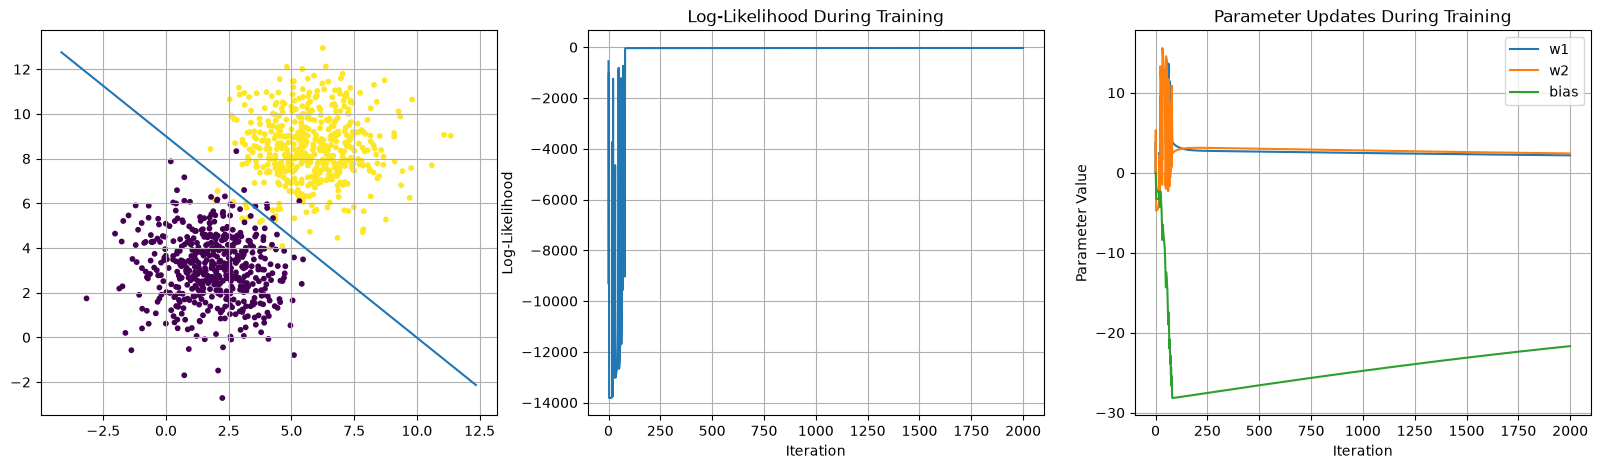

In [38]:
# Plot
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].scatter(df['X0'], df['X1'], s= 10, c=df['Y'])

x0 = np.linspace(start=df['X0'].min()-1, stop=df['X0'].max()+ 1, num=300)
y1 = -((lgr.bias) + (lgr.weights[0] * x0)) / lgr.weights[1]
ax[0].plot(x0, y1)

ax[0].grid()

ax[1].plot(lgr.loss_history)

ax[1].set_xlabel("Iteration")
ax[1].set_ylabel("Log-Likelihood")
ax[1].set_title("Log-Likelihood During Training")
ax[1].grid()



weights_history = np.array(lgr.weights_history)


ax[2].plot(weights_history[:, 0], label="w1")
ax[2].plot(weights_history[:, 1], label="w2")
ax[2].plot(weights_history[:, 2], label="bias")

ax[2].set_xlabel("Iteration")
ax[2].set_ylabel("Parameter Value")
ax[2].set_title("Parameter Updates During Training")
ax[2].grid()
plt.legend()

plt.show()